# Bench D: OTA in its loop

The PMOS-input OTA of the NMOS cascode as a unity-gain buffer, its output held at the gate level it has in bench C. `vos = v(inn) − v(inp)` is the input-referred offset at that output level.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from sarlib import specs as S
from sarlib.analysis import load_real, parse_op_log, eng, log_cross, window_around, Report

DATA = Path('simulation/ota_p_ac.sch')
o = S.ota_p
GAIN_MIN = o.SPECS['gain_db_min']
rep = Report()

## Open-loop gain

A0 43.9 dB, f-3dB 491 kHz, fu 81.2 MHz, PM 45.6 deg, GM 8.7 dB at 278 MHz


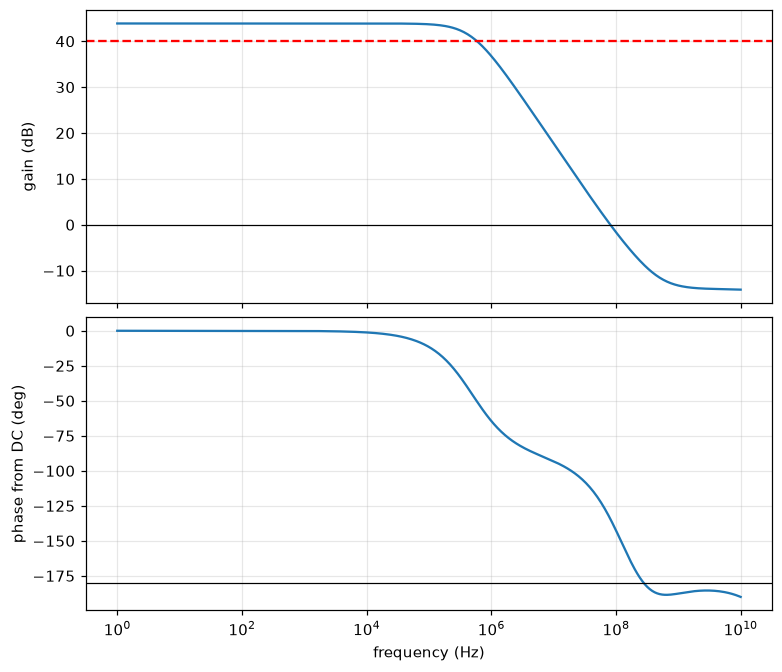

In [2]:
f, (db, ph) = load_real(DATA / 'ac.csv')
rel = ph - ph[0]
f3db = log_cross(f, db, db[0] - 3.0)
fu = log_cross(f, db, 0.0)
pm = 180 + np.interp(np.log10(fu), np.log10(f), rel)
f180 = log_cross(f, rel, -180.0)
print(f'A0 {db[0]:.1f} dB, f-3dB {eng(f3db, "Hz")}, fu {eng(fu, "Hz")}, PM {pm:.1f} deg, '
      f'GM {-np.interp(np.log10(f180), np.log10(f), db):.1f} dB at {eng(f180, "Hz")}')
rep.check('DC gain at the held output level', f'{db[0]:.1f} dB', f'>= {GAIN_MIN:.0f} dB', db[0] >= GAIN_MIN)
rep.info('unity-gain frequency (with load)', eng(fu, 'Hz'))
rep.info('phase margin, OTA in unity feedback', f'{pm:.1f} deg')

fig, ax = plt.subplots(2, 1, figsize=(7, 6), sharex=True)
ax[0].semilogx(f, db); ax[0].axhline(0, c='k', lw=0.8); ax[0].axhline(GAIN_MIN, c='r', ls='--'); ax[0].set_ylabel('gain (dB)')
ax[1].semilogx(f, rel); ax[1].axhline(-180, c='k', lw=0.8); ax[1].set(xlabel='frequency (Hz)', ylabel='phase from DC (deg)')
plt.show()

## Input common-mode range

Window around V_CM where the offset stays within 1 mV of its value at V_CM.

offset -1.377 mV, window 0.05 to 0.77 V (need 0.15 to 0.35), CMRR 61.4 dB


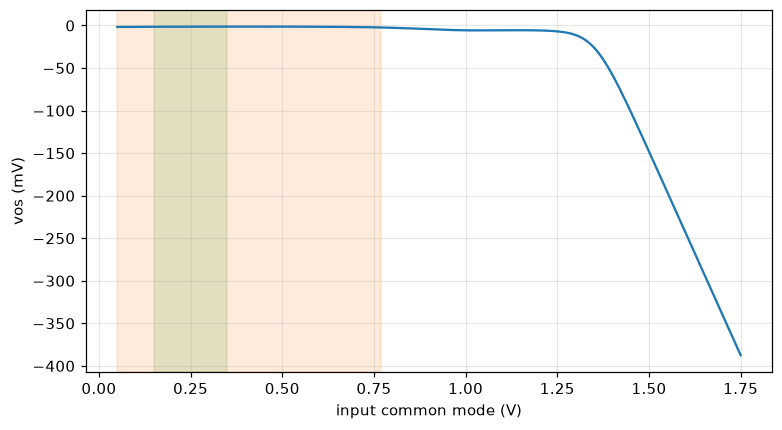

In [3]:
x, (vos, idd) = load_real(DATA / 'cm_sweep.csv')
need = (o.VCM - o.CM_MARGIN, o.VCM + o.CM_MARGIN)
v0 = np.interp(o.VCM, x, vos)
w_cm = window_around(x, np.abs(vos - v0) < 1e-3 * o.SPECS['cm_tol_mv'], o.VCM)
m = (x >= need[0]) & (x <= need[1])
cmrr = -20 * np.log10(abs(np.polyfit(x[m], vos[m], 1)[0]))
step = np.median(np.diff(x))
covers = bool(w_cm and w_cm[0] <= need[0] + 0.5 * step and w_cm[1] >= need[1] - 0.5 * step)
print(f'offset {1e3 * v0:.3f} mV, window {w_cm[0]:.2f} to {w_cm[1]:.2f} V (need {need[0]:.2f} to {need[1]:.2f}), CMRR {cmrr:.1f} dB')
rep.check('input common-mode range covers V_CM +/- margin', 'yes' if covers else 'no', 'yes', covers)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(x, 1e3 * vos); ax.axvspan(*need, color='g', alpha=0.12); ax.axvspan(*w_cm, color='C1', alpha=0.15)
ax.set(xlabel='input common mode (V)', ylabel='vos (mV)')
plt.show()

## Output range

Local DC gain from the offset slope: A = 1/|d vos / d V_out| − 1 (3-point median).

gain above spec for 0.39 to 1.18 V; min over 0.99-1.06 V: 43.5 dB


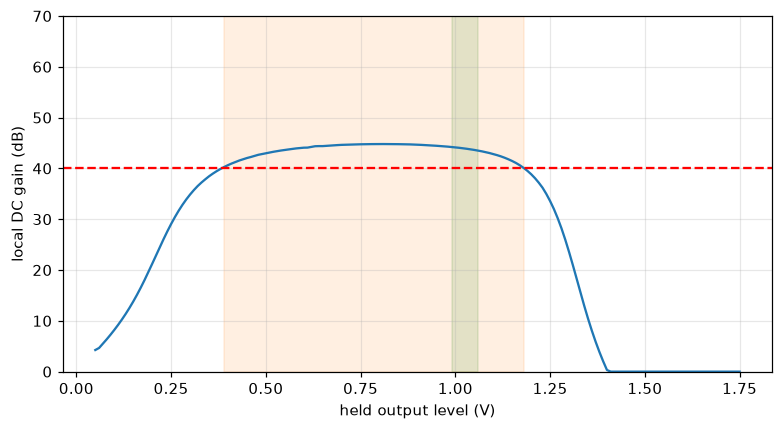

In [4]:
x, (vos, idd) = load_real(DATA / 'vo_sweep.csv')
a = np.clip(1 / np.abs(np.gradient(vos, x)) - 1, 1.0, 1e12)
a[1:-1] = np.median(np.stack([a[:-2], a[1:-1], a[2:]]), axis=0)
gdb = 20 * np.log10(a)
w_vo = window_around(x, gdb >= GAIN_MIN, o.VO)
inside = (x >= o.VO_NEED[0]) & (x <= o.VO_NEED[1])
gmin = gdb[inside].min()
step = np.median(np.diff(x))
covers = bool(w_vo and w_vo[0] <= o.VO_NEED[0] + 0.5 * step and w_vo[1] >= o.VO_NEED[1] - 0.5 * step)
print(f'gain above spec for {w_vo[0]:.2f} to {w_vo[1]:.2f} V; min over {o.VO_NEED[0]:.2f}-{o.VO_NEED[1]:.2f} V: {gmin:.1f} dB')
rep.check('min DC gain over the needed output range', f'{gmin:.1f} dB', f'>= {GAIN_MIN:.0f} dB', gmin >= GAIN_MIN)
rep.check('output range covers the loop', 'yes' if covers else 'no', 'yes', covers)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(x, gdb); ax.axhline(GAIN_MIN, c='r', ls='--'); ax.axvspan(*o.VO_NEED, color='g', alpha=0.12)
ax.axvspan(*w_vo, color='C1', alpha=0.12); ax.set(xlabel='held output level (V)', ylabel='local DC gain (dB)', ylim=(0, 70))
plt.show()

## Summary

In [5]:
idd = max(parse_op_log(DATA / n)['idd'] for n in ('op_nom.log', 'op_volo.log', 'op_vohi.log'))
rep.info('supply current (max over output levels)', eng(idd, 'A'))
rep.table()

,check,value,spec,result
0,DC gain at the held output level,43.9 dB,>= 40 dB,PASS
1,unity-gain frequency (with load),81.2 MHz,,INFO
2,"phase margin, OTA in unity feedback",45.6 deg,,INFO
3,input common-mode range covers V_CM +/- margin,yes,yes,PASS
4,min DC gain over the needed output range,43.5 dB,>= 40 dB,PASS
5,output range covers the loop,yes,yes,PASS
6,supply current (max over output levels),19.8 uA,,INFO
